In [213]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection  import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [214]:
data = pd.read_csv("winequality-red.csv")
print(data.head())

print(data.shape)

   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]
(1599, 12)


In [215]:
data.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [216]:
print(data.columns)
print(data.dtypes)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [217]:
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [218]:
# Feaytures And Target

x = data.drop("quality", axis=1) # Features 
y = data["quality"] # Target

# Standdrdize the Features 

scalar = StandardScaler()
x_scaled = scalar.fit_transform(x)


In [219]:
# Apply PCA

pca = PCA(n_components=2)
x_pca =pca.fit_transform(x_scaled)

print("Veriance Ratio = ",pca.explained_variance_ratio_)
print("Total Veriance = ", sum(pca.explained_variance_ratio_))

Veriance Ratio =  [0.28173931 0.1750827 ]
Total Veriance =  0.4568220118429404


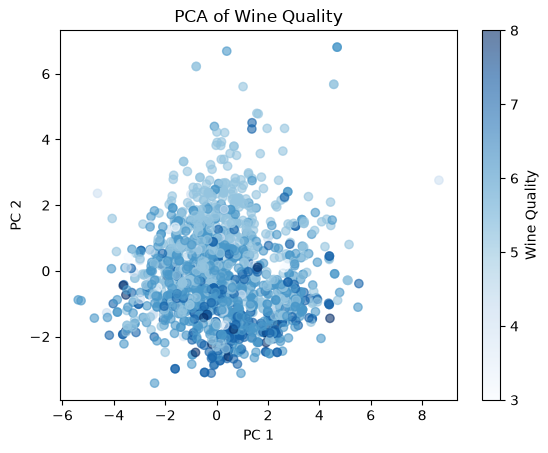

In [220]:
plt.Figure(figsize=(10,7))
scatter = plt.scatter(x_pca[:,0],x_pca[:,1],c=y,cmap="Blues", alpha = 0.6)
plt.colorbar(scatter,label="Wine Quality")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("PCA of Wine Quality")

plt.show()

Text(0.5, 1.0, 'PCA of Wine Quality')

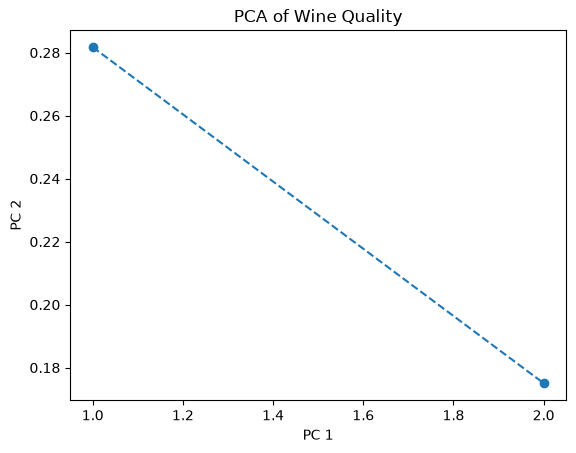

In [221]:
# Scree Plot -> Verience Per component

plt.plot(range(1,3),pca.explained_variance_ratio_,marker ="o",linestyle = "--")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("PCA of Wine Quality")


In [223]:
# Split the data (80% Train, 20% Test) after PCA 
x_train, x_test, y_train, y_test = train_test_split(
    x_pca, y,
    test_size=0.2,
    random_state=42
)

clf = RandomForestClassifier(random_state=42)
clf.fit(x_train, y_train)
y_pred = clf.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy (PCA Data):", accuracy)



# Split the data (80% Train, 20% Test) of original data

x_train_o, x_test_o, y_train_o, y_test_o = train_test_split(
    x_scaled , y,
    test_size=0.2,
    random_state=42
)

clf = RandomForestClassifier(random_state=42)
clf.fit(x_train_o, y_train_o)
y_pred_o = clf.predict(x_test_o)

accuracy_o = accuracy_score(y_test_o, y_pred_o)
print("Accuracy (Original Data):", accuracy_o)



Accuracy (PCA Data): 0.5375
Accuracy (Original Data): 0.65
